### Utility Libraries

In [ ]:
!pip install -q timm albumentations
!pip install torchmetrics


In [ ]:
import kagglehub
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
import gc
import cv2
import timm
import random
import re

from tqdm import tqdm
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
import albumentations as A
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from torchmetrics.classification import BinaryAUROC, BinaryAccuracy
from torch.amp import GradScaler, autocast

# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


### Kaggle Login & Data Download

In [ ]:
kagglehub.login()

In [ ]:
os.environ['KAGGLEHUB_CACHE'] = "./data"
path = kagglehub.competition_download("multimodal-cancer-classification-challenge-2026")


### Data Exploration

Visualizing samples with labels from train.csv:


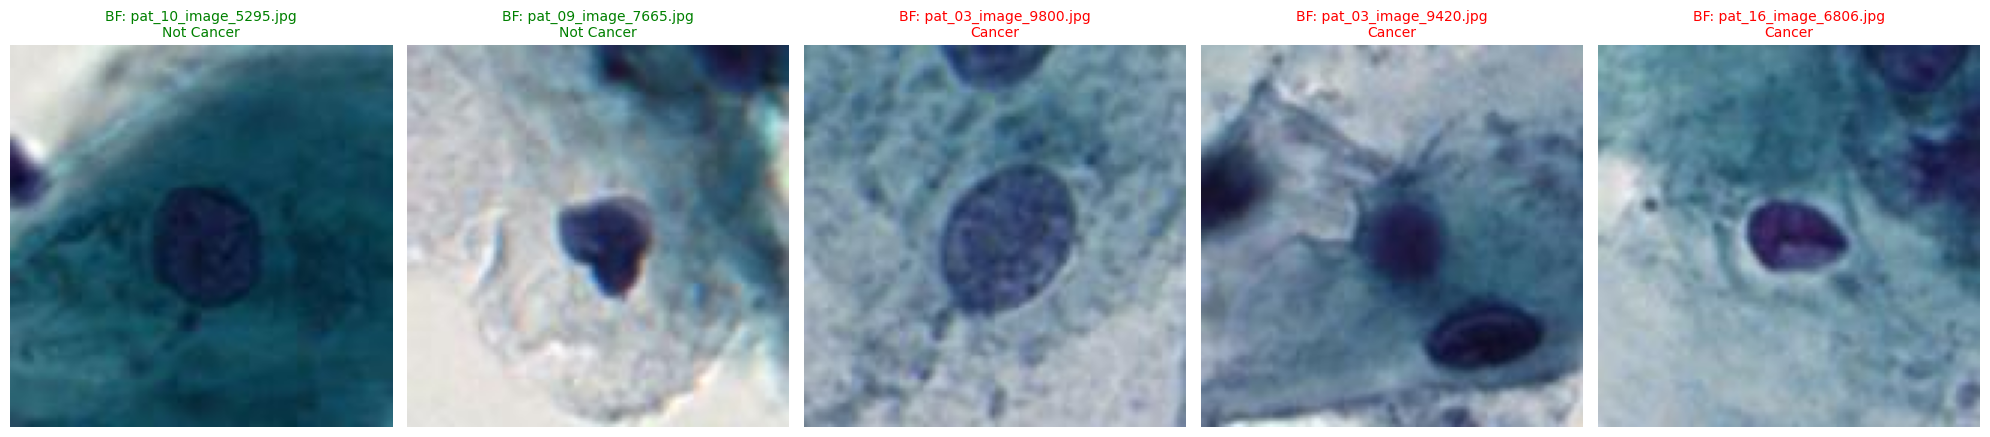

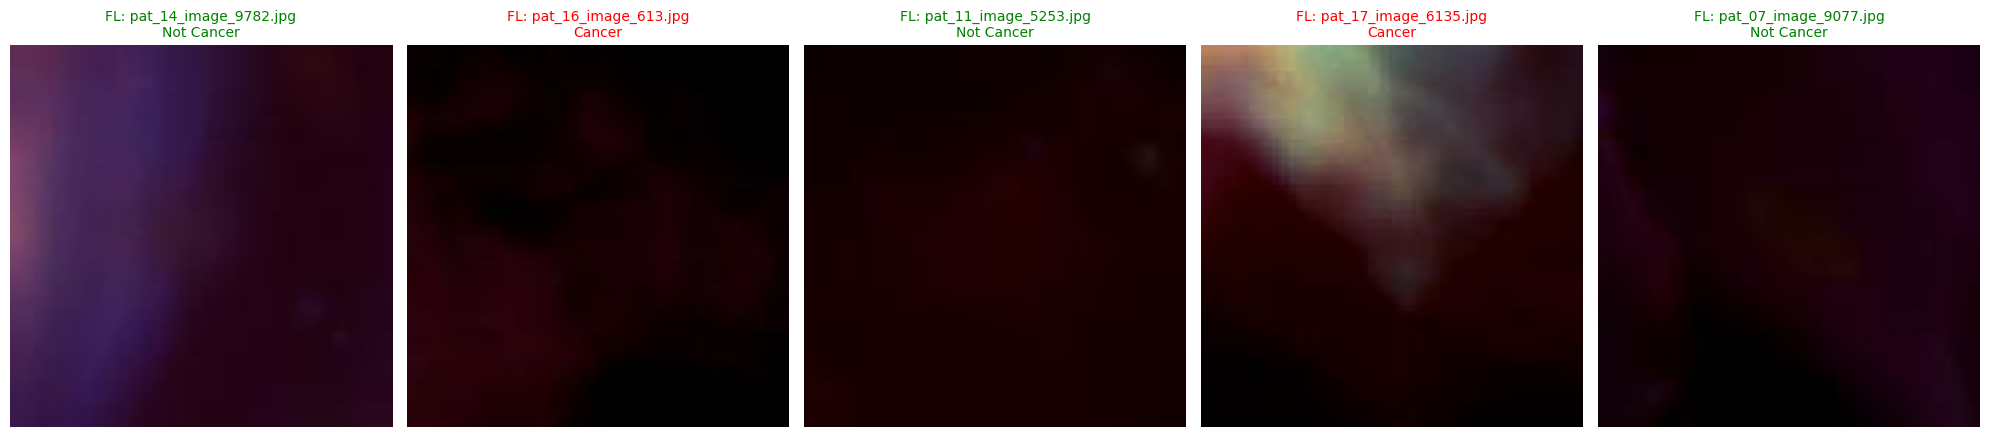

In [ ]:
# Load the latest labels from the competition directory
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Define paths for Bright Field and Fluorescence training images
BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')

# Mapping for human-readable titles
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

# Get lists of available image files
BF_Images_list = [f for f in os.listdir(BF_Images) if f.lower().endswith(('.jpg'))]
FL_Images_list = [f for f in os.listdir(FL_Images) if f.lower().endswith(('.jpg'))]

random.shuffle(BF_Images_list)
random.shuffle(FL_Images_list)

def plot_labeled_samples(img_list, base_path, title_prefix):
    fig, ax = plt.subplots(1, 5, figsize=(20, 5))
    for i in range(5):
        img_name = img_list[i]
        img_path = os.path.join(base_path, img_name)
        img = cv2.imread(img_path)

        # Search for the diagnosis in the train_df based on filename
        match = train_df[train_df['Name'] == img_name]
        if not match.empty:
            label_val = match.iloc[0]['Diagnosis']
            label_text = diagnosis_map.get(label_val, 'Unknown')
        else:
            label_text = "Not Found in CSV"

        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax[i].imshow(img)
            title_color = 'red' if label_text == 'Cancer' else 'green' if label_text == 'Not Cancer' else 'black'
            ax[i].set_title(f"{title_prefix}: {img_name}\n{label_text}", color=title_color, fontsize=10)
        ax[i].axis("off")
    plt.tight_layout()
    plt.show()

print("Visualizing samples with labels from train.csv:")
plot_labeled_samples(BF_Images_list, BF_Images, "BF")
plot_labeled_samples(FL_Images_list, FL_Images, "FL")

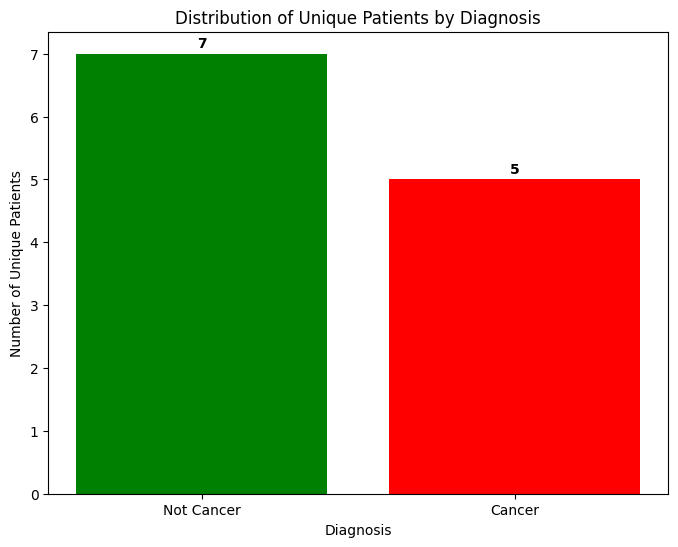

Total unique patients: 12


In [ ]:
# Using train_df consistently for data exploration
# Pattern assumes 'pat_XX_image_YY.jpg'
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

# Get the diagnosis per patient
patient_diagnosis = train_df.groupby('Patient')['Diagnosis'].first().reset_index()

# Count the number of patients for each diagnosis
diagnosis_counts = patient_diagnosis['Diagnosis'].value_counts().sort_index()

# Plotting
plt.figure(figsize=(8, 6))
colors = ['green', 'red']
labels_map = {0: 'Not Cancer', 1: 'Cancer'}
diagnosis_names = [labels_map[i] for i in diagnosis_counts.index]

plt.bar(diagnosis_names, diagnosis_counts.values, color=colors[:len(diagnosis_counts)])
plt.xlabel('Diagnosis')
plt.ylabel('Number of Unique Patients')
plt.title('Distribution of Unique Patients by Diagnosis')

for i, count in enumerate(diagnosis_counts.values):
    plt.text(i, count + 0.1, str(count), ha='center', fontweight='bold')

plt.show()

print(f"Total unique patients: {len(patient_diagnosis)}")

In [ ]:
num_patients = train_df['Patient'].nunique()
print(f"There are {num_patients} unique patients in the dataset.")

There are 12 unique patients in the dataset.


In [ ]:
# Load the labels and setup paths immediately after downloading
labels_path = os.path.join(path, 'train.csv')
train_df = pd.read_csv(labels_path)

# Extract Patient ID immediately to ensure consistency across all downstream tasks
train_df['Patient'] = train_df['Name'].apply(lambda x: re.match(r'(pat_\d+)', x).group(1))

BF_Images = os.path.join(path, 'BF', 'train')
FL_Images = os.path.join(path, 'FL', 'train')
diagnosis_map = {0: 'Not Cancer', 1: 'Cancer'}

print(f"Loaded {len(train_df)} samples and extracted patient IDs.")

Loaded 114302 samples and extracted patient IDs.


In [ ]:
# Initialize GroupKFold based on the Patient ID column created in the loading step
gkf = GroupKFold(n_splits=3)
train_df['fold'] = -1

for fold, (train_idx, val_idx) in enumerate(gkf.split(train_df, train_df['Diagnosis'], groups=train_df['Patient'])):
    train_df.loc[val_idx, 'fold'] = fold

print(f"Fold distribution:\n{train_df['fold'].value_counts()}")
print(f"Unique patients per fold check:\n{train_df.groupby('fold')['Patient'].nunique()}")

Fold distribution:
fold
1    40000
0    40000
2    34302
Name: count, dtype: int64
Unique patients per fold check:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


In [ ]:
import pandas as pd

# Ensure we use train_df which contains the patient and fold info
if 'train_df' in globals() and 'fold' in train_df.columns:
    df_to_check = train_df
else:
    df_to_check = None

if df_to_check is not None:
    # Check if each patient belongs to only one fold
    patient_fold_counts = df_to_check.groupby('Patient')['fold'].nunique()
    is_valid_split = (patient_fold_counts == 1).all()
    print(f"Is every patient assigned to exactly one fold? {is_valid_split}")

    # Display the mapping of Patient to Fold
    patient_to_fold = df_to_check.groupby(['Patient', 'fold']).size().reset_index(name='Image_Count')
    display(patient_to_fold.head())

    # Summary of how many patients are in each fold
    fold_summary = patient_to_fold.groupby('fold')['Patient'].count()
    print('\nNumber of patients per fold:')
    print(fold_summary)
else:
    print('Error: Could not find train_df with fold assignments. Please ensure the GroupKFold cell has been executed.')

Is every patient assigned to exactly one fold? True


,Patient,fold,Image_Count
0,pat_03,1,10000
1,pat_05,2,4302
2,pat_07,0,10000
3,pat_09,2,10000
4,pat_10,1,10000



Number of patients per fold:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


In [ ]:
import pandas as pd

# Ensure we use the labels dataframe which has the patient and fold info
if 'labels' in globals() and 'fold' in labels.columns:
    df_to_check = labels
elif 'train_df' in globals() and 'fold' in train_df.columns:
    df_to_check = train_df
else:
    df_to_check = None

if df_to_check is not None:
    # Check if each patient belongs to only one fold
    patient_fold_counts = df_to_check.groupby('Patient')['fold'].nunique()
    is_valid_split = (patient_fold_counts == 1).all()

    # print(f"Is every patient assigned to exactly one fold? {is_valid_split}")

    # Display the mapping of Patient to Fold
    patient_to_fold = df_to_check.groupby(['Patient', 'fold']).size().reset_index(name='Image_Count')
    display(patient_to_fold)

    # Summary of how many patients are in each fold
    fold_summary = patient_to_fold.groupby('fold')['Patient'].count()
    print('\nNumber of patients per fold:')
    print(fold_summary)
else:
    print('Error: Could not find a dataframe with fold assignments. Please ensure the GroupKFold cell has been executed.')

,Patient,fold,Image_Count
0,pat_03,1,10000
1,pat_05,2,4302
2,pat_07,0,10000
3,pat_09,2,10000
4,pat_10,1,10000
5,pat_11,0,10000
6,pat_13,2,10000
7,pat_14,1,10000
8,pat_15,0,10000
9,pat_16,2,10000



Number of patients per fold:
fold
0    4
1    4
2    4
Name: Patient, dtype: int64


In [ ]:
# Calculate total image counts for each diagnosis
cancer_images = len(train_df[train_df['Diagnosis'] == 1])
not_cancer_images = len(train_df[train_df['Diagnosis'] == 0])

print(f"Total images with Cancer: {cancer_images}")
print(f"Total images with Not Cancer: {not_cancer_images}")
print(f"Grand Total: {len(train_df)}")

Total images with Cancer: 44302
Total images with Not Cancer: 70000
Grand Total: 114302


### Data Loader and Augmentation

In [ ]:
class MultimodalCancerDataset(Dataset):
    def __init__(self, df, bf_dir, fl_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']
        label = torch.tensor(self.df.loc[idx, 'Diagnosis'], dtype=torch.long)

        # Load BF Image
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL Image
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            # Pass both simultaneously
            augmented = self.transform(image=bf_img, image_fl=fl_img)
            augmented_bf = augmented['image']
            augmented_fl = augmented['image_fl']
            return torch.cat([augmented_bf, augmented_fl], dim=0), label

        return (bf_img, fl_img), label

In [ ]:
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Af
    # A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2),
        A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10),
    ], p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), # 3-channel
    ToTensorV2(),
], additional_targets={'image_fl': 'image'}) # Sync transformations

val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), # 3-channel
    ToTensorV2(),
], additional_targets={'image_fl': 'image'}) # Sync transformations

train_ds = MultimodalCancerDataset(train_df[train_df['fold'] != 0], BF_Images, FL_Images, transform=train_transform)
valid_ds = MultimodalCancerDataset(train_df[train_df['fold'] == 0], BF_Images, FL_Images, transform=val_transform)

# Optimization: Increase num_workers and use pin_memory for faster GPU transfer
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train dataset size: {len(train_ds)}")
print(f"Validation dataset size: {len(valid_ds)}")

Train dataset size: 74302
Validation dataset size: 40000


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
# class BaselineResNet50(nn.Module):
#     def __init__(self, pretrained=True):
#         super(BaselineResNet50, self).__init__()

#         # FIX: Add drop_rate=0.5 to inject Dropout before the final classification head
#         self.model = timm.create_model('resnet50', pretrained=pretrained, num_classes=1, drop_rate=0.4)

#         old_conv = self.model.conv1
#         self.model.conv1 = nn.Conv2d(6, old_conv.out_channels,
#                                     kernel_size=old_conv.kernel_size,
#                                     stride=old_conv.stride,
#                                     padding=old_conv.padding,
#                                     bias=old_conv.bias)

#         if pretrained:
#             with torch.no_grad():
#                 self.model.conv1.weight[:, :3, :, :] = old_conv.weight
#                 self.model.conv1.weight[:, 3:, :, :] = old_conv.weight

#         # FIX: Strategic Layer Freezing
#         for name, param in self.model.named_parameters():
#             # Freeze everything by default
#             param.requires_grad = False

#             # UNFREEZE: conv1 (because it's new), layer4 (for fine-tuning), and fc (classifier)
#             if 'conv1' in name or 'layer4' in name or 'fc' in name or 'global_pool' in name:
#                 param.requires_grad = True

#     def forward(self, x):
#         return self.model(x)

### New Model (ResNet50)

In [ ]:
class BaselineResNet50(nn.Module):
    def __init__(self, pretrained=True):
        super(BaselineResNet50, self).__init__()
        # Remove num_classes=1 here to handle the head manually
        self.model = timm.create_model('resnet50', pretrained=pretrained, num_classes=0)

        # 1. Modify the input convolution
        old_conv = self.model.conv1
        self.model.conv1 = nn.Conv2d(6, old_conv.out_channels,
                                    kernel_size=old_conv.kernel_size,
                                    stride=old_conv.stride,
                                    padding=old_conv.padding, bias=False)

        # Initialize weights
        if pretrained:
            with torch.no_grad():
                self.model.conv1.weight[:, :3, :, :] = old_conv.weight
                self.model.conv1.weight[:, 3:, :, :] = old_conv.weight.mean(dim=1, keepdim=True)

        # 2. Add a custom Bottleneck Classifier
        embed_dim = self.model.num_features # 2048 for ResNet50
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(embed_dim, 512),
            nn.GELU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.6),
            nn.Linear(512, 1)
        )

        # 3. Freeze Early Layers
        for name, param in self.model.named_parameters():
            if 'conv1' not in name and 'layer4' not in name:
                param.requires_grad = False

    def forward(self, x):
        features = self.model(x)
        return self.classifier(features)

In [ ]:
model_resnet = BaselineResNet50(pretrained=True).to(device)
print("Baseline ResNet50 (6-channel input) initialized.")

Baseline ResNet50 (6-channel input) initialized.


### Version 1 - 77.8%. - Without MixUp

In [ ]:
# def train_one_epoch(model, loader, optimizer, criterion, device, scaler):
#     model.train()
#     total_loss = 0
#     auroc_metric = BinaryAUROC().to(device)

#     for images, labels in tqdm(loader, desc="Training"):
#         images, labels = images.to(device), labels.to(device).float().view(-1, 1)

#         optimizer.zero_grad()
#         with autocast("cuda"):
#             outputs = model(images)
#             loss = criterion(outputs, labels)

#         scaler.scale(loss).backward()
#         scaler.step(optimizer)
#         scaler.update()

#         total_loss += loss.item()
#         auroc_metric.update(torch.sigmoid(outputs), labels.int())

#     return total_loss / len(loader), auroc_metric.compute().item()

# def validate(model, loader, criterion, device):
#     model.eval()
#     total_loss = 0
#     auroc_metric = BinaryAUROC().to(device)
#     acc_metric = BinaryAccuracy().to(device)

#     with torch.no_grad():
#         for images, labels in tqdm(loader, desc="Validation"):
#             images, labels = images.to(device), labels.to(device).float().view(-1, 1)
#             with autocast("cuda"):
#                 outputs = model(images)
#                 loss = criterion(outputs, labels)

#             total_loss += loss.item()
#             probs = torch.sigmoid(outputs)
#             auroc_metric.update(probs, labels.int())
#             acc_metric.update(probs, labels.int())

#     return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

### Version 2 - 80.55% - With MixUp

In [ ]:
# --- Helper: Mixup Implementation ---
def mixup_data(x, y, alpha=0.2):
    lam = torch.distributions.beta.Beta(alpha, alpha).sample().to(x.device)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def train_one_epoch(model, loader, optimizer, criterion, device, scaler, use_mixup=True):
    model.train()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    auroc_metric.reset() # CRITICAL: Reset metrics every epoch

    for images, labels in tqdm(loader, desc="Training"):
        images, labels = images.to(device), labels.to(device).float().view(-1, 1)

        # Apply Mixup Augmentation
        if use_mixup:
            images, targets_a, targets_b, lam = mixup_data(images, labels)

        optimizer.zero_grad()
        with autocast("cuda"):
            outputs = model(images)

            # --- LABEL SMOOTHING ---
            smoothing = 0.1
            if use_mixup:
                loss = lam * F.binary_cross_entropy_with_logits(outputs, targets_a * (1-smoothing) + 0.5*smoothing) + \
                       (1 - lam) * F.binary_cross_entropy_with_logits(outputs, targets_b * (1-smoothing) + 0.5*smoothing)
            else:
                loss = F.binary_cross_entropy_with_logits(outputs, labels * (1 - smoothing) + 0.5 * smoothing)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        auroc_metric.update(torch.sigmoid(outputs), labels.int())

    return total_loss / len(loader), auroc_metric.compute().item()

def validate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    auroc_metric = BinaryAUROC().to(device)
    acc_metric = BinaryAccuracy().to(device)

    auroc_metric.reset() # CRITICAL: Reset metrics every epoch
    acc_metric.reset()

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device).float().view(-1, 1)
            with autocast("cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.sigmoid(outputs)
            auroc_metric.update(probs, labels.int())
            acc_metric.update(probs, labels.int())

    return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

### Version 3

In [ ]:
# # --- Helper: Mixup Implementation ---
# def mixup_data(x, y, alpha=0.2):
#     lam = torch.distributions.beta.Beta(alpha, alpha).sample().to(x.device)
#     batch_size = x.size()[0]
#     index = torch.randperm(batch_size).to(x.device)
#     mixed_x = lam * x + (1 - lam) * x[index, :]
#     y_a, y_b = y, y[index]
#     return mixed_x, y_a, y_b, lam


# def train_one_epoch(model, loader, optimizer, criterion, device, scaler, scheduler, use_mixup=True):
#     model.train()
#     total_loss = 0
#     auroc_metric = BinaryAUROC().to(device)
#     auroc_metric.reset()

#     for images, labels in tqdm(loader, desc="Training"):
#         images, labels = images.to(device), labels.to(device).float().view(-1, 1)

#         # Apply Mixup Augmentation
#         if use_mixup:
#             images, targets_a, targets_b, lam = mixup_data(images, labels)

#         optimizer.zero_grad()
#         with autocast("cuda"):
#             outputs = model(images)

#             # --- LABEL SMOOTHING ---
#             smoothing = 0.1
#             if use_mixup:
#                 # Smoothing applied to both Mixup targets
#                 loss = lam * F.binary_cross_entropy_with_logits(outputs, targets_a * (1 - smoothing) + 0.5 * smoothing) + \
#                        (1 - lam) * F.binary_cross_entropy_with_logits(outputs, targets_b * (1 - smoothing) + 0.5 * smoothing)
#             else:
#                 loss = F.binary_cross_entropy_with_logits(outputs, labels * (1 - smoothing) + 0.5 * smoothing)

#         # 1. Backward pass
#         scaler.scale(loss).backward()

#         # 2. Update model weights
#         scaler.step(optimizer)

#         # 3. Update the scale factor for next iteration
#         scaler.update()

#         # 4. Zero out gradients for the next batch
#         optimizer.zero_grad()

#         # 5. NOW step the scheduler
#         scheduler.step()

#         total_loss += loss.item()
#         auroc_metric.update(torch.sigmoid(outputs), labels.int())

#     return total_loss / len(loader), auroc_metric.compute().item()


# def validate(model, loader, criterion, device):
#     model.eval()
#     total_loss = 0
#     auroc_metric = BinaryAUROC().to(device)
#     acc_metric = BinaryAccuracy().to(device)

#     auroc_metric.reset()
#     acc_metric.reset()

#     with torch.no_grad():
#         for images, labels in tqdm(loader, desc="Validation"):
#             images, labels = images.to(device), labels.to(device).float().view(-1, 1)
#             with autocast("cuda"):
#                 outputs = model(images)
#                 # Use standard loss for validation (no smoothing/mixup)
#                 loss = criterion(outputs, labels)

#             total_loss += loss.item()
#             probs = torch.sigmoid(outputs)
#             auroc_metric.update(probs, labels.int())
#             acc_metric.update(probs, labels.int())

#     return total_loss / len(loader), auroc_metric.compute().item(), acc_metric.compute().item()

### Version 1 - 77.8%

In [ ]:
# EPOCHS = 25 # Give it more time to learn the unfrozen layers
# learning_rate = 1e-4

# # FIX: Class imbalance handling (adjust the 3.0 based on your actual Cancer/Not Cancer ratio)
# pos_weight_value = torch.tensor([3.0]).to(device)
# criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_value)

# # FIX: Filter unfrozen parameters and increase weight decay
# trainable_params = filter(lambda p: p.requires_grad, model_resnet.parameters())
# optimizer = AdamW(trainable_params, lr=learning_rate, weight_decay=5e-2)

# scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

# # Initialize GradScaler for AMP
# scaler = GradScaler("cuda")

# history = {'train_loss': [], 'train_auc': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}
# best_val_auc = 0

# for epoch in range(EPOCHS):
#     train_loss, train_auc = train_one_epoch(model_resnet, train_loader, optimizer, criterion, device, scaler)
#     val_loss, val_auc, val_acc = validate(model_resnet, valid_loader, criterion, device)

#     scheduler.step(val_auc)

#     history['train_loss'].append(train_loss)
#     history['train_auc'].append(train_auc)
#     history['val_loss'].append(val_loss)
#     history['val_auc'].append(val_auc)
#     history['val_acc'].append(val_acc)

#     print(f"\nEpoch {epoch+1}/{EPOCHS}")
#     print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
#     print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

#     if val_auc > best_val_auc:
#         best_val_auc = val_auc
#         torch.save(model_resnet.state_dict(), 'best_model.pth')
#         print("*** Best Model Saved ***")

### Version 2 - 80.55%

In [ ]:
# --- Configuration ---
EPOCHS = 25
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 5e-2
EARLY_STOPPING_PATIENCE = 5  # Stop if no improvement for 5 epochs
POS_WEIGHT = torch.tensor([1.58]).to(device) # Adjust based on your specific dataset ratio

# --- Setup ---
trainable_params = filter(lambda p: p.requires_grad, model_resnet.parameters())
optimizer = AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
criterion = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
scaler = GradScaler("cuda")

# --- Tracking ---
history = {'train_loss': [], 'train_auc': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}
best_val_auc = 0
early_stopping_counter = 0

print("Starting training...")

# --- Training Loop ---
for epoch in range(EPOCHS):
    # Train with Label Smoothing (via the updated train_one_epoch function)
    train_loss, train_auc = train_one_epoch(
        model_resnet, train_loader, optimizer, criterion, device, scaler
    )

    # Validate
    val_loss, val_auc, val_acc = validate(
        model_resnet, valid_loader, criterion, device
    )

    # Scheduler Step
    scheduler.step(val_auc)

    # Record History
    history['train_loss'].append(train_loss)
    history['train_auc'].append(train_auc)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)
    history['val_acc'].append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train AUC: {train_auc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val AUC: {val_auc:.4f} | Val Acc: {val_acc:.4f}")

    # Best Model Saving
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model_resnet.state_dict(), 'best_model.pth')
        print("*** Best Model Saved ***")
        early_stopping_counter = 0  # Reset on improvement
    else:
        early_stopping_counter += 1
        print(f"No improvement for {early_stopping_counter} epochs.")

    # Early Stopping Trigger
    if early_stopping_counter >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping triggered at epoch {epoch+1}. Best Val AUC: {best_val_auc:.4f}")
        break

Starting training...


Validation: 100%|██████████| 1250/1250 [02:02<00:00, 10.21it/s]



Epoch 1/25
Train Loss: 0.5639 | Train AUC: 0.6800
Val Loss: 0.4916 | Val AUC: 0.8843 | Val Acc: 0.8100
*** Best Model Saved ***


Validation: 100%|██████████| 1250/1250 [01:58<00:00, 10.57it/s]



Epoch 2/25
Train Loss: 0.4709 | Train AUC: 0.7251
Val Loss: nan | Val AUC: 0.8986 | Val Acc: 0.8233
*** Best Model Saved ***


Validation: 100%|██████████| 1250/1250 [01:57<00:00, 10.67it/s]



Epoch 3/25
Train Loss: 0.4382 | Train AUC: 0.7327
Val Loss: nan | Val AUC: 0.8889 | Val Acc: 0.8217
No improvement for 1 epochs.


Training:  19%|█▉        | 446/2322 [01:09<05:05,  6.15it/s]

### Test & Submission

In [ ]:
class MultimodalTestDataset(Dataset):
    def __init__(self, test_df, bf_dir, fl_dir, transform=None):
        self.df = test_df.reset_index(drop=True)
        self.bf_dir = bf_dir
        self.fl_dir = fl_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'Name']

        # Load BF
        bf_path = os.path.join(self.bf_dir, img_name)
        bf_img = cv2.imread(bf_path)
        bf_img = cv2.cvtColor(bf_img, cv2.COLOR_BGR2RGB)

        # Load FL
        fl_path = os.path.join(self.fl_dir, img_name)
        fl_img = cv2.imread(fl_path)
        fl_img = cv2.cvtColor(fl_img, cv2.COLOR_BGR2RGB)

        if self.transform:
            augmented_bf = self.transform(image=bf_img)['image']
            augmented_fl = self.transform(image=fl_img)['image']
            return torch.cat([augmented_bf, augmented_fl], dim=0), img_name
        else:
            # Ensure consistent 6-channel output even without transforms
            bf_tensor = torch.from_numpy(bf_img).permute(2, 0, 1).float() / 255.0
            fl_tensor = torch.from_numpy(fl_img).permute(2, 0, 1).float() / 255.0
            return torch.cat([bf_tensor, fl_tensor], dim=0), img_name

# Load sample submission to get test file names
test_df = pd.read_csv(os.path.join(path, 'sampleSubmission.csv'))

# Note: Assuming test images are in 'BF/test' and 'FL/test'
BF_Test = os.path.join(path, 'BF', 'test')
FL_Test = os.path.join(path, 'FL', 'test')

# Use val_transform for testing to ensure deterministic resizing and normalization
test_ds = MultimodalTestDataset(test_df, BF_Test, FL_Test, transform=val_transform)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

In [ ]:
# Load the best weights before inference
model_resnet.load_state_dict(torch.load('best_model.pth'))
model_resnet.eval()

predictions = []
file_names = []

with torch.no_grad():
    for images, names in tqdm(test_loader, desc="Testing"):
        images = images.to(device)
        with autocast("cuda"):
            outputs = model_resnet(images)
        probs = torch.sigmoid(outputs).cpu().numpy()
        predictions.extend(probs.flatten())
        file_names.extend(names)

submission = pd.DataFrame({'Name': file_names, 'Diagnosis': predictions})
submission.to_csv('submission.csv', index=False)
print("Submission file saved.")
display(submission.head())

Testing: 100%|██████████| 923/923 [02:56<00:00,  5.22it/s]


Submission file saved.


/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,Name,Diagnosis
0,image_1.jpg,0.382324
1,image_2.jpg,0.429932
2,image_3.jpg,0.247681
3,image_4.jpg,0.057587
4,image_5.jpg,0.653809
